# 해커톤 v2 오전 Colab 실습: 데이터 탐색과 저수율 판별·검증

45분 동안 수율이 포함된 연습 데이터를 탐색하고(EDA), 저수율과 관련 있어 보이는 입력을 찾아 판별 모델을 비교합니다. 실제 수율을 기준으로 모델 결과를 검증한 뒤, 탐색에서 검증까지의 흐름을 오후 팀 과제에 응용합니다.

**Colab:** `v2_train_10800.csv` 하나만 파일 패널의 `/content`에 업로드하고 위에서부터 실행하세요. 로컬에서는 v2 폴더의 `data/`를 읽습니다. 수율이 숨겨진 파일과 제출 CSV는 오전에 사용하지 않습니다.


In [1]:
%pip install -q pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


## 0. 원본 데이터와 저수율 라벨 확인하기

**실행 전:** 한 행은 웨이퍼 한 장입니다. 먼저 `shape`로 행과 열 수를, `head()`로 첫 5행을 확인하세요. `wafer_id`는 행을 식별하는 번호입니다. `production_date`, `equipment_id`, `recipe_id`, `shift`는 생산 맥락이고, `S01`~`S08`은 익명 센서 측정값입니다. `yield_rate`는 실제 수율(%), `yield_status`는 저수율 여부를 나타내는 정답 라벨입니다. 수율과 라벨은 모델 입력에 넣지 않습니다.


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

train_name = 'v2_train_10800.csv'
locations = (Path('data'), Path('../data'), Path('해커톤_v2_데이터/data'), Path.cwd())
folder = next((path for path in locations if (path / train_name).is_file()), None)
if folder is None:
    raise FileNotFoundError(f'{train_name}을 업로드하세요.')
train = pd.read_csv(folder / train_name, parse_dates=['production_date'])
dates = sorted(train['production_date'].unique())
if len(dates) != 45 or train['production_date'].isna().any():
    raise ValueError('연습용 v2 데이터의 생산 날짜 45일을 확인하세요.')


In [3]:
row_count, column_count = train.shape
print(f'연습용: {row_count:,}행 × {column_count}열')
print(f'생산 날짜: {dates[0]:%Y-%m-%d} ~ {dates[-1]:%Y-%m-%d}')
display(train.head())

# 열마다 어떤 값이 들어 있고 비어 있는 값은 몇 개인지 확인합니다.
column_info = pd.DataFrame({'자료형': train.dtypes.astype(str), '결측 수': train.isna().sum()})
display(column_info)

# 학습에 사용할 날짜만 먼저 보고, 저수율 라벨이 얼마나 드문지 확인합니다.
learning_labels = train.loc[train['production_date'] < dates[25], 'yield_status']
label_counts = learning_labels.value_counts().rename('건수').to_frame()
label_counts['비율 (%)'] = (label_counts['건수'] / len(learning_labels) * 100).round(2)
print('앞 25일의 수율 라벨 분포')
display(label_counts)


연습용: 10,800행 × 15열
생산 날짜: 2025-10-01 ~ 2025-11-14


,wafer_id,production_date,equipment_id,recipe_id,shift,S01,S02,S03,S04,S05,S06,S07,S08,yield_rate,yield_status
0,P3-00001,2025-10-01,ETCH-A,R1,DAY,99.0,97.77,25.45,47.28,194.63,36.81,23.14,24.87,93,NORMAL
1,P3-00002,2025-10-01,ETCH-A,R2,NIGHT,103.0,102.33,24.29,47.03,200.77,39.68,22.86,24.31,97,NORMAL
2,P3-00003,2025-10-01,ETCH-A,R3,DAY,107.0,107.05,25.00,46.66,207.95,41.69,21.76,24.38,96,NORMAL
3,P3-00004,2025-10-01,ETCH-A,R1,NIGHT,99.0,98.46,25.82,45.82,189.55,38.56,23.54,23.94,97,NORMAL
4,P3-00005,2025-10-01,ETCH-A,R2,DAY,103.0,102.72,25.84,47.85,201.93,39.04,22.91,23.97,96,NORMAL


,자료형,결측 수
wafer_id,str,0
production_date,datetime64[us],0
equipment_id,str,0
recipe_id,str,0
shift,str,0
S01,float64,0
S02,float64,0
S03,float64,0
S04,float64,0
S05,float64,0


앞 25일의 수율 라벨 분포


,건수,비율 (%)
yield_status,,
NORMAL,5906,98.43
LOW,94,1.57


**실행 후:** 10,800행·15열과 생산 날짜 범위를 확인하고, 센서 열의 자료형과 결측 수를 살펴보세요. 마지막 표에서는 앞 25일의 `NORMAL`·`LOW` 건수와 비율을 비교합니다. 마지막 평가 구간의 실제 수율은 여기서 집계하지 않습니다. 저수율이 드물다면 모든 웨이퍼를 정상으로 보고도 정확도가 높아 보일 수 있습니다.


## 1. 날짜순으로 학습·모델 선택·최종 평가 데이터 나누기

앞 25일은 학습, 다음 10일은 모델·설정 선택, 마지막 10일은 최종 확인입니다. 세 구간 모두 같은 연습용 CSV 안에 있습니다. 날짜를 섞으면 가까운 미래의 센서 분포가 학습에 들어가 성능이 실제보다 좋아 보일 수 있습니다. 탐색 중에는 5단계까지만 실행하고, 설정을 확정한 뒤에만 6단계를 실행하세요.


In [4]:
learn_end, select_end = dates[25], dates[35]
learn = train.loc[train['production_date'] < learn_end]
select = train.loc[train['production_date'].between(learn_end, select_end, inclusive='left')]
test = train.loc[train['production_date'] >= select_end]
print(f'학습 {len(learn):,}장 / 모델 선택 {len(select):,}장 / 최종 확인 {len(test):,}장')


학습 6,000장 / 모델 선택 2,400장 / 최종 확인 2,400장


## 2. 센서 8개의 장비별 일별 중앙값 그리기

**실행 전:** 학습 구간에서 센서 8개와 장비 4대의 일별 중앙값을 한 화면에 그립니다. 센서마다 단위와 값의 범위가 다를 수 있어 축을 따로 둡니다. 그래프 하나는 센서 하나, 색이 다른 선은 장비 한 대, 점 하나는 그 날짜·장비의 중앙값입니다. 수율을 그린 것이 아닙니다.


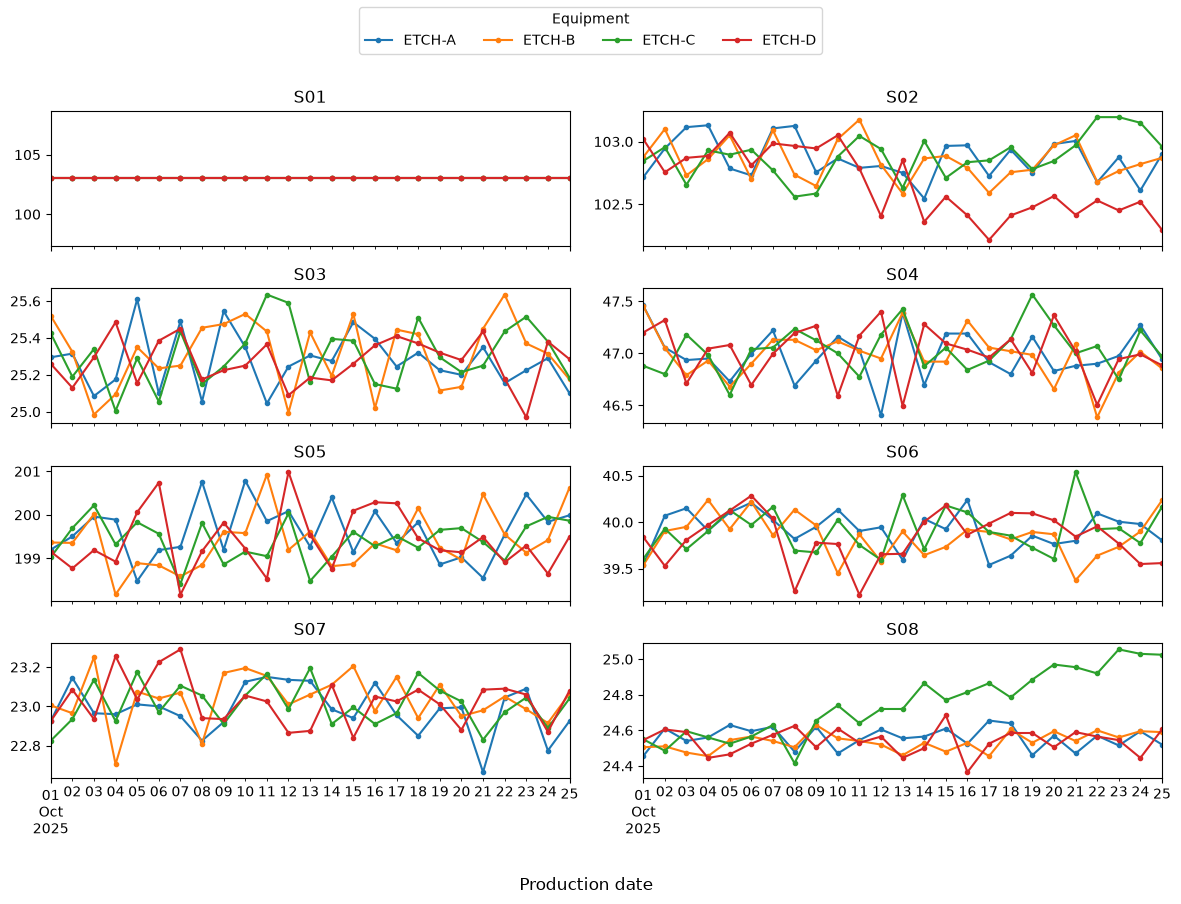

In [5]:
overview_sensors = [f'S{number:02d}' for number in range(1, 9)]
overview_daily = learn.groupby(['production_date', 'equipment_id'])[overview_sensors].median()
overview_figure, overview_axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True)
for overview_sensor, overview_axis in zip(overview_sensors, overview_axes.flat):
    overview_daily[overview_sensor].unstack().plot(ax=overview_axis, marker='.', title=overview_sensor, legend=False)
    overview_axis.set_xlabel('')
handles, labels = overview_axes[0, 0].get_legend_handles_labels()
overview_figure.legend(handles, labels, loc='upper center', ncol=4, title='Equipment')
overview_figure.supxlabel('Production date')
overview_figure.tight_layout(rect=(0, 0.02, 1, 0.92))
plt.show()


### 2.1 S01의 선은 한 개일까요, 네 개가 겹친 걸까요?

**실행 전:** 그래프에 사용한 `S01` 중앙값을 표로 확인합니다. 한 행은 생산 날짜 하루, 한 열은 장비 한 대입니다. 같은 날짜의 장비 네 대 값을 가로로 비교해 보세요.


In [6]:
s01_daily = overview_daily['S01'].unstack('equipment_id')
display(s01_daily.head())
same_days = s01_daily.notna().all(axis=1) & s01_daily.nunique(axis=1).eq(1)
print(f'장비별 S01 중앙값이 모두 같은 날: {same_days.sum()}일 / {len(s01_daily)}일')


equipment_id,ETCH-A,ETCH-B,ETCH-C,ETCH-D
production_date,,,,
2025-10-01,103.0,103.0,103.0,103.0
2025-10-02,103.0,103.0,103.0,103.0
2025-10-03,103.0,103.0,103.0,103.0
2025-10-04,103.0,103.0,103.0,103.0
2025-10-05,103.0,103.0,103.0,103.0


장비별 S01 중앙값이 모두 같은 날: 25일 / 25일


**실행 후:** 표에 장비 열이 네 개 있는데 값이 같다면, 장비가 한 대만 그려진 것이 아니라 네 선이 같은 위치에 겹친 것입니다. 여기까지는 날짜별 **중앙값**이 같다는 뜻입니다. 다음 셀에서는 날짜나 장비로 묶지 않고 원본 값을 직접 봅니다.


### 2.2 원본 S01 값이 여러 개인지 확인하기

**실행 전:** 일별 중앙값이 모두 같다면, 개별 웨이퍼의 `S01`도 모두 같을까요? 학습 구간의 원본에서 서로 다른 `S01` 값과 각 값에 해당하는 웨이퍼 수를 확인합니다.


In [7]:
s01_raw_counts = learn['S01'].value_counts(dropna=False).sort_index()
display(s01_raw_counts.rename('웨이퍼 수').to_frame())


,웨이퍼 수
S01,
99.0,2100
103.0,2100
107.0,1800


**실행 후:** 표에 서로 다른 숫자가 여러 개 보인다면, 중앙값이 같아도 원본은 같은 값만 가진 것이 아닙니다. 그렇다면 이 값들은 **무엇에 따라 달라질까요?** `recipe_id`는 웨이퍼에 적용한 공정 조건을 구분하는 열입니다. 여러 값이 공정 조건별로 나뉘는지 확인하기 위해 다음 셀에서 레시피를 후보로 살펴봅니다.


### 2.3 레시피별로 센서 8개 비교하기

**실행 전:** `recipe_id`로 묶어 전체 센서의 **고유값 수**와 **중앙값**을 먼저 봅니다. `S01`이 같은 레시피 안에서 일정한지 확인한 뒤, 여러 레시피에서 중앙값이 각각 `S01`에 가까운 열을 후보로 고르세요. 숫자가 비슷하다는 사실만으로 두 센서가 같은 물리량이라고 단정할 수는 없습니다.


In [8]:
recipe_groups = learn.groupby('recipe_id')[overview_sensors]
print('레시피별 고유값 수')
display(recipe_groups.nunique())
print('레시피별 중앙값')
display(recipe_groups.median().round(2))


레시피별 고유값 수


,S01,S02,S03,S04,S05,S06,S07,S08
recipe_id,,,,,,,,
R1,1,325,473,606,929,390,331,182
R2,1,327,454,618,900,384,327,177
R3,1,314,448,562,849,360,318,177


레시피별 중앙값


,S01,S02,S03,S04,S05,S06,S07,S08
recipe_id,,,,,,,,
R1,99.0,98.95,25.30,46.93,192.58,37.60,23.02,24.60
R2,103.0,102.94,25.31,47.05,199.85,40.05,23.00,24.59
R3,107.0,106.93,25.27,47.04,206.90,42.32,23.04,24.59


#### 고른 센서와 S01의 값 범위 비교하기

**실행 전:** 위 중앙값 표에서 레시피 행마다 `S01`과 가까운 열을 찾아 `RECIPE_CANDIDATE`에 넣으세요. 아래 표에서 `min`·`median`·`max`는 최솟값·중앙값·최댓값입니다.


In [ ]:
RECIPE_CANDIDATE = ''


In [10]:
if not RECIPE_CANDIDATE:
    print('위 표에서 후보를 고르고 설정 셀과 이 셀을 다시 실행하세요.')
elif RECIPE_CANDIDATE not in overview_sensors[1:]:
    raise ValueError('S02~S08 중 하나를 고르세요.')
else:
    recipe_summary = learn.groupby('recipe_id')[['S01', RECIPE_CANDIDATE]].agg(['nunique', 'min', 'median', 'max'])
    display(recipe_summary.round(2))


S01                          S02                        
          nunique    min median    max nunique     min  median     max
recipe_id                                                             
R1              1   99.0   99.0   99.0     325   96.50   98.95  101.05
R2              1  103.0  103.0  103.0     327  100.81  102.94  105.11
R3              1  107.0  107.0  107.0     314  104.81  106.93  109.47

**실행 후: 표에서 근거를 찾아 가설을 써 보세요.**

1. 같은 레시피 안에서 값이 하나뿐인 열은 어느 쪽인가요? 다른 레시피로 바꾸면 그 값도 바뀌나요?
2. 같은 레시피에서 다른 열의 중앙값은 그 한 값과 얼마나 가까운가요? 최솟값과 최댓값도 비교해 보세요.
3. “`___`가 레시피별 기준값처럼 보인다. `___` 자체보다 그 기준에서 얼마나 벗어났는지 보면 장비별 변화가 더 잘 보일 수 있다.” 빈칸을 채우고, 표에서 확인한 숫자를 근거로 하나 적으세요.


### 2.4 같은 센서에서 장비 네 대의 변화 비교하기

**실행 전:** 레시피 표에서는 어떤 값을 비교할지 정했습니다. 이제 어느 장비를 자세히 볼지 정합니다. 2번 그래프에 쓴 일별 중앙값을 가져와 장비마다 첫 5일의 중앙값과 마지막 5일의 중앙값을 비교합니다. 표의 값은 **마지막 5일 − 첫 5일**입니다. 센서 단위가 다를 수 있으므로 한 행에서 장비 네 대만 비교하세요.


In [11]:
first_days = overview_daily.loc[dates[:5]].groupby('equipment_id').median()
last_days = overview_daily.loc[dates[20:25]].groupby('equipment_id').median()
equipment_change = (last_days - first_days).T
display(equipment_change.round(3))


equipment_id,ETCH-A,ETCH-B,ETCH-C,ETCH-D
S01,0.000,0.000,0.000,0.000
S02,-0.070,-0.055,0.255,-0.435
S03,-0.070,0.045,0.090,0.025
S04,-0.005,-0.075,0.120,-0.135
S05,0.335,0.195,0.040,0.140
S06,-0.090,-0.190,0.030,-0.070
S07,-0.040,-0.020,0.035,0.045
S08,-0.040,0.085,0.475,0.020


**실행 후:** 그래프에서 눈에 띈 센서의 행을 골라, 어느 장비가 가장 내려갔는지 또는 올라갔는지 찾아보세요. `센서 ___ / 장비 ___ / 변화 ___`를 적고, 같은 센서에서 비교할 다른 장비도 고르세요. 이 표는 자세히 볼 후보를 고르는 근거이지 저수율의 원인을 확인한 결과는 아닙니다.

**가설 검증 계획:** 3번을 실행하기 전에 아래 질문에 답하세요.

1. **무엇을 비교할까요?** 원래 센서값과 기준값을 뺀 차이 중 어느 쪽에서 장비별 변화가 더 잘 보일지 예상합니다. 표에서 고른 센서와 비교할 장비를 적으세요.
2. **무엇을 고정할까요?** 원래 값과 차이를 공정하게 비교하려면 두 그래프에서 같은 장비와 날짜 구간을 봐야 합니다. 비교할 장비와 기간을 적으세요. 그래프를 그리는 방법은 3번에서 확인합니다.
3. **무엇이 보이면 가설을 지지할까요?** 예를 들어 ‘특정 장비의 선이 다른 장비와 여러 날 연속으로 벌어진다’처럼, 그래프를 보기 전에 확인할 기준을 한 문장으로 적으세요.


### 2.5 비교할 센서와 장비 설정하기

**실행 후:** 8개 그래프에서 장비 선이 오래 벌어지거나 한쪽으로 움직이는 곳을 찾아보세요. 전체 그림만으로는 특정 날짜의 움직임이나 선이 겹치는 구간을 자세히 보기 어렵습니다. 관심 센서와 장비를 골라 3번에서 다시 그리세요. 찾기 어렵다면 우선 아래 기본값으로 시작한 뒤, 센서나 장비를 하나씩 바꾸며 비교하세요. 선택한다고 원본 행이 삭제되지는 않습니다.

- `SENSOR_COLUMNS`: 그래프로 볼 센서이며, 이후 모델에도 입력으로 사용합니다.
- `PLOT_EQUIPMENT`: 그래프에 표시할 장비만 고릅니다. 학습 대상 장비는 그대로입니다.
- `USE_GAP`: 켜면 두 센서의 차이인 `flow_gap = S02 - S01`을 그래프와 모델 입력에 추가합니다.


In [ ]:
SENSOR_COLUMNS = ['S03']
PLOT_EQUIPMENT = ['ETCH-A']
USE_GAP = False


## 3. 원래 센서값과 차이 그래프 비교하기

**실행 전:** `S02` 원래 값과 `flow_gap`을 비교하려면 2.5 설정에서 `SENSOR_COLUMNS`에 `S02`를 넣고, 계획에서 고른 장비를 `PLOT_EQUIPMENT`에 지정한 뒤 `USE_GAP=True`로 두세요. 설정 셀을 실행하고 아래 그래프 셀을 **한 번** 실행하면 원래 값과 차이 그래프가 함께 나옵니다.

학습 구간에서만 장비별 일별 중앙값을 그립니다. 가로축은 생산 날짜, 세로축은 센서값 또는 두 센서의 차이입니다. 점 하나는 웨이퍼 한 장이 아니라 **하루·장비의 대표값**입니다. 센서별 단위가 다를 수 있으므로 그림을 따로 그립니다.

**`flow_gap` 읽는 법 (`USE_GAP=True`):** 웨이퍼마다 `S02 - S01`을 계산합니다. 두 값이 같으면 0, `S02`가 더 크면 양수, 더 작으면 음수입니다. 예를 들어 `S01=100`, `S02=98.5`면 `flow_gap=-1.5`입니다. 그래프의 각 점은 그날 그 장비에서 구한 차이들의 중앙값입니다. 음수라는 이유만으로 이상은 아닙니다. 같은 장비의 평소 값에서 차이가 여러 날 같은 방향으로 움직이는지 관찰하세요. 이 그림만으로 실제 공정 원인을 단정할 수는 없습니다.


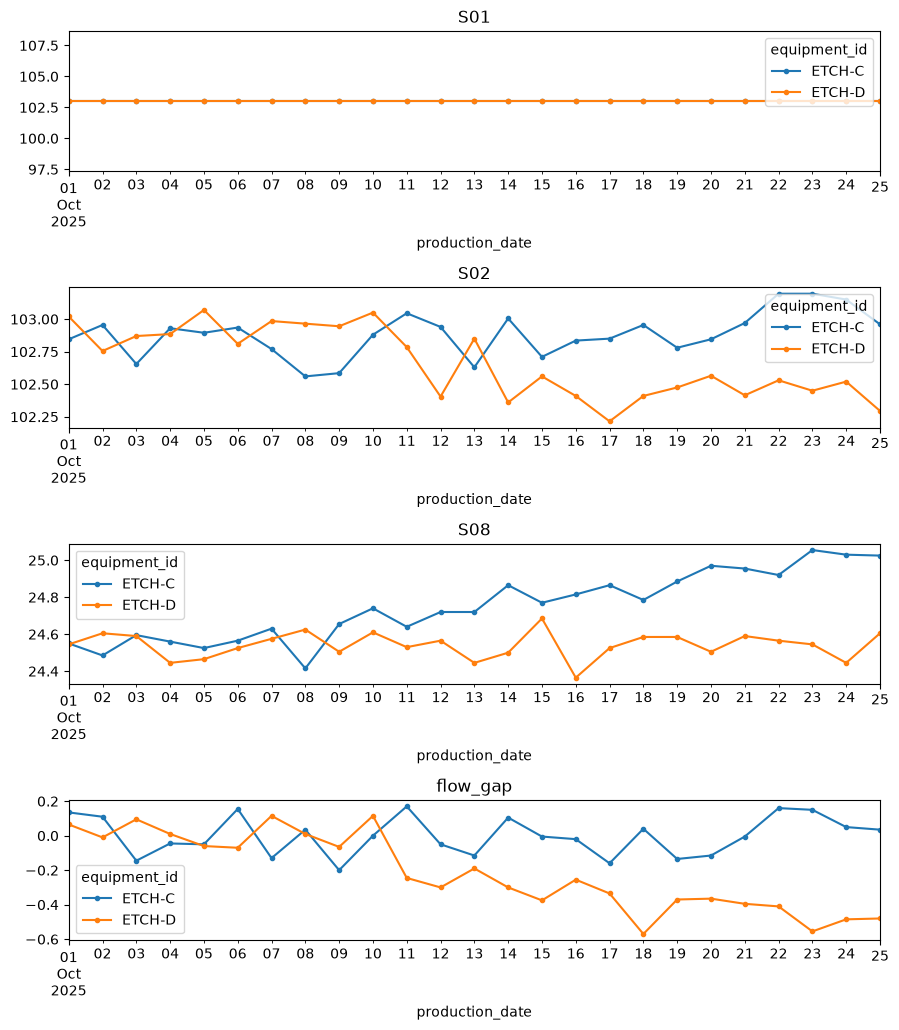

In [13]:
allowed_sensors = {f'S{number:02d}' for number in range(1, 9)}
if not SENSOR_COLUMNS or not set(SENSOR_COLUMNS) <= allowed_sensors:
    raise ValueError('S01~S08 중 하나 이상의 센서를 고르세요.')
features = list(dict.fromkeys(SENSOR_COLUMNS))
if USE_GAP:
    features.append('flow_gap')

def sensor_frame(rows):
    frame = rows.copy()
    if USE_GAP:
        frame['flow_gap'] = frame['S02'] - frame['S01']
    return frame

visible = sensor_frame(learn)
visible = visible.loc[visible['equipment_id'].isin(PLOT_EQUIPMENT)]
if visible.empty:
    raise ValueError('ETCH-A~ETCH-D 중 표시할 장비를 고르세요.')
daily_plot = visible.groupby(['production_date', 'equipment_id'])[features].median()
figure, axes = plt.subplots(len(features), 1, figsize=(9, 2.6 * len(features)), squeeze=False)
for feature, axis in zip(features, axes[:, 0]):
    daily_plot[feature].unstack().plot(ax=axis, marker='.', title=feature)
figure.tight_layout()
plt.show()


**3번 실행 후: 예상과 관찰을 비교하세요.** 한 번에 출력된 원래 값과 차이 그래프를 비교하고, 고른 장비와 날짜 구간에서 눈에 띈 숫자나 변화 방향을 기록하세요. 그래프마다 세로축 범위가 다를 수 있으니 선이 더 가파르게 보인다는 이유만으로 판단하지 마세요. 한 날짜의 튐과 여러 날 이어지는 변화를 구분합니다.

**기록 양식:** `비교한 장비·기간: ___ / 원래 값에서 본 것: ___ / 차이에서 본 것: ___ / 결론: 지지·지지하지 않음·근거 부족`. 결론 옆에 날짜와 값을 근거로 하나 적으세요. 이 비교는 센서 변화가 더 잘 드러나는지 보는 것이며, 저수율 판별에 더 유용한지는 5번에서 확인합니다. 실제 센서 역할이나 공정 원인을 입증한 것은 아닙니다.


### 3번 정리: 지금까지 확인한 것과 다음에 검증할 것

- **데이터:** 실제 수율이 있는 10,800장을 날짜순으로 나눴고, 지금까지의 센서 탐색은 앞 25일만 사용했습니다.
- **관찰:** 일별 중앙값의 선이 겹쳐도 개별 웨이퍼 값까지 같은 것은 아닙니다. 원본과 레시피별 표에서 확인한 사실을 적으세요: `___`.
- **가설:** 같은 장비·날짜에서 원래 센서값과 기준 대비 차이를 비교했습니다. `장비 ___ / 신호 ___ / 관찰한 변화 ___`를 적으세요. 센서의 물리적 원인이나 저수율 판별 성능을 입증한 것은 아닙니다.

**왜 모델 입력으로 바꾸나요?** 3번 그래프의 점은 하루·장비의 대표값이라서, 그것만 보고 어느 웨이퍼가 저수율인지 판단할 수는 없습니다. 모델이 웨이퍼 한 장씩 판단할 수 있도록 그 웨이퍼의 **원래 센서값**(측정된 수준)과 **기준 대비 차이**(기준보다 얼마나 높거나 낮은지)를 각각 숫자 열로 넣어 봅니다. 센서값 자체가 모델이 되는 것이 아닙니다. 모델은 이 입력과 앞 25일의 실제 저수율 라벨을 보고 관계를 학습합니다. 그래프에서 눈에 띈 값이라도 실제 판별에 도움이 되는지는 아직 모릅니다.

**이제 할 일:** 4번에서는 웨이퍼별 입력 열을 만듭니다. 5번에서는 같은 모델·날짜·검사 장수에서 원래 값만 쓸 때와 차이를 더할 때의 Precision@67을 비교해, 실제 저수율을 더 잘 찾는지 확인합니다. 마지막 10일은 선택을 끝낸 뒤 6번에서만 평가합니다.


## 4. 웨이퍼별 모델 입력과 정답 만들기

**실행 전:** 3번 그래프의 점은 날짜·장비의 대표값이었지만, 모델은 웨이퍼 한 장씩 판별합니다. `X`에는 2.5에서 고른 각 웨이퍼의 센서값과 `USE_GAP=True`일 때의 `flow_gap`만 넣습니다. `y`는 실제 저수율(`LOW`)이면 1, 아니면 0인 정답입니다. 실제 수율과 라벨은 `X`에 넣지 않습니다.

**실행 후:** 첫 5장 입력 표에서 고른 센서와 `flow_gap` 열이 설정과 일치하는지 확인하세요. 센서나 `USE_GAP`을 바꿔 비교하려면 2.5 설정부터 5번까지 다시 실행합니다.


In [ ]:
X = sensor_frame(train[sorted(allowed_sensors)])[features]
y = train['yield_status'].eq('LOW').astype(int)
display(X.head())


## 5. 저수율 판별 모델 3개 비교하기

- **로지스틱 회귀:** 이름에 회귀가 들어가지만 여기서는 `LOW` 확률을 예측하는 분류 모델입니다. 여러 입력을 합친 선형 경계가 충분한 상황에서 해석하기 좋습니다.
- **얕은 결정 트리:** ‘이 값 이상인가?’라는 조건 분기가 어울리는 문제에 유용합니다. 스케일에 덜 민감하지만 깊어지면 잡음까지 외울 수 있습니다.
- **KNN:** 가까운 웨이퍼의 라벨을 참고하므로, 스케일을 맞추지 않으면 큰 단위의 센서가 거리를 지배합니다. 센서가 많고 불량이 드물면 이웃이 대부분 정상일 수도 있습니다.

**왜 67장인가요?** 오후 과제의 검사 한도인 **3,600장 중 100장**과 같은 비율을 적용합니다. 오전의 모델 선택 구간과 최종 평가 구간은 각각 2,400장이므로, `2,400 × (100 / 3,600) ≈ 66.67`을 반올림해 **구간마다 최대 67장**을 검사합니다. 실제 저수율 장수가 아니라 모든 모델에 똑같이 적용하는 검사 한도입니다.

결측 대체와 표준화는 학습 행에서만 학습합니다. **Precision@K = 상위 K장 중 실제 저수율 수 / K**입니다. ROC-AUC는 전체 순위, AP(평균 정밀도)는 희소한 `LOW`에 대한 정밀도·재현율을 요약합니다. 여기서는 Precision@67을 우선하고, 동률이면 AP를 봅니다.


세 모델은 항상 모두 비교합니다. `MODEL_CHOICE`는 다음 최종 확인 단계에 넘길 모델만 정합니다. `'auto'`는 모델 선택 구간의 Precision@K와 AP 순서로 추천합니다.


In [ ]:
MODEL_CHOICE = 'logistic'


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 모델별 전처리와 분류기를 묶습니다.
models = {
    'logistic': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000)),
    'tree': make_pipeline(SimpleImputer(strategy='median'), DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, random_state=42)),
    'knn': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights='distance')),
}
inspection_budget = 67

def rank_risk(rows, risk):
    # 확률에 원래 행 번호를 붙여 정렬한 뒤에도 같은 웨이퍼의 정답을 찾을 수 있게 합니다.
    # 안정 정렬은 확률이 같을 때 원래 행 순서를 유지합니다.
    return pd.Series(risk, index=rows.index).sort_values(ascending=False, kind='stable')

def score_metrics(rows, risk):
    labels = y.loc[rows.index]
    count = min(inspection_budget, len(rows))
    rank = rank_risk(rows, risk)
    # 확률 상위 67장(또는 가능한 장수)을 고른 뒤에만 실제 라벨을 확인합니다. LOW는 1입니다.
    hits = int(labels.loc[rank.head(count).index].sum())
    total_low = int(labels.sum())
    # 적중/누락과 Precision@K는 제한된 검사 장수 기준, ROC-AUC와 AP는 전체 구간 기준입니다.
    return {'K': count, 'LOW': total_low, 'hits': hits, 'misses': total_low - hits,
            'precision_at_k': hits / count, 'recall_at_k': hits / total_low if total_low else float('nan'),
            'random_precision': labels.mean(), 'roc_auc': roc_auc_score(labels, risk),
            'average_precision': average_precision_score(labels, risk)}

selection = {}
for name, model in models.items():
    # 앞 25일의 센서 입력 X와 실제 라벨 y로만 전처리와 모델을 학습합니다.
    model.fit(X.loc[learn.index], y.loc[learn.index])
    # 다음 10일에는 다시 학습하지 않습니다. [:, 1]은 클래스 1(LOW)의 확률만 가져옵니다.
    probabilities = model.predict_proba(X.loc[select.index])[:, 1]
    selection[name] = score_metrics(select, probabilities)
# 먼저 같은 검사 예산에서 더 잘 찾은 모델을 보고, 동률이면 AP를 비교합니다.
leaderboard = pd.DataFrame.from_dict(selection, orient='index').sort_values(
    ['precision_at_k', 'average_precision'], ascending=False, kind='stable')
display(leaderboard.round(3))
# auto는 표의 1위, 직접 지정하면 그 모델을 마지막 10일 평가로 넘깁니다.
chosen = leaderboard.index[0] if MODEL_CHOICE == 'auto' else MODEL_CHOICE
print(f'최종 확인에 사용할 모델: {chosen}')


### 5번 결과 읽기: 어떤 지표를 봐야 할까요?

일반적인 분류에서는 먼저 어느 점수부터 `LOW`라고 판정할지 정합니다. 그런 다음 혼동 행렬에서 **맞힌 LOW·잘못 고른 정상·놓친 LOW·맞힌 정상**의 네 가지 건수를 확인합니다.

| 일반적인 분류 지표 | 답하는 질문 |
| --- | --- |
| 정확도(Accuracy) | 전체 중 몇 장을 맞혔나요? 저수율이 2%라면 전부 정상으로 답해도 98%이므로, 정확도만으로는 부족합니다. |
| 정밀도(Precision) | `LOW`라고 고른 것 중 실제 `LOW`는 얼마나 되나요? |
| 재현율(Recall) | 실제 `LOW` 전체 중 얼마를 찾아냈나요? |
| F1 | 정밀도와 재현율의 조화평균입니다. 둘 중 하나가 낮으면 함께 낮아집니다. |

이번에는 확률 0.5 같은 기준으로 판정하지 않고, **위험도 순으로 최대 67장**만 검사합니다. 그래서 위 지표 중 정밀도와 재현율을 검사 예산에 맞춰 읽습니다.

| 이번 실습에서 볼 지표 | 읽는 법 |
| --- | --- |
| Precision@67 (우선) | `hits / K`. 고른 67장 중 실제 저수율 비율입니다. 모두 같은 장수를 고르므로 적중 수를 직접 비교해도 됩니다. |
| Recall@67 및 누락 | `recall_at_k = hits / LOW`. 분모 `LOW`는 평가 기간의 실제 저수율 전체입니다. `misses`는 그중 놓친 장수입니다. |
| 무작위 기준 | `random_precision`은 평가 구간의 실제 `LOW` 비율이자 무작위로 고를 때 기대할 수 있는 정밀도입니다. |
| AP (동률 판단) | 상위 67장만이 아니라 순위를 더 넓게 보며, 실제 `LOW`를 앞쪽에 얼마나 잘 모았는지 정밀도와 재현율로 요약합니다. |
| ROC-AUC (참고) | 임의의 `LOW` 한 장을 임의의 정상 한 장보다 위험하게 순위 매기는 정도입니다. 높아도 상위 67장 적중이 더 높다는 보장은 없습니다. |

예를 들어 실제 저수율 50장 중 20장을 찾았다면 Precision@67은 `20 / 67`(29.9%), Recall@67은 `20 / 50`(40%), 누락은 30장입니다. **5번의 같은 기간 결과끼리** 비교하고, 마지막 10일의 6번 결과는 설정 확정 후에만 확인합니다.


## 6. 마지막 10일에서 선택한 모델 평가하기

**왜 따로 평가하나요?** 앞 25일은 모델을 학습하는 데, 다음 10일(5번)은 모델과 센서 설정을 고르는 데 썼습니다. 5번에서 잘 나온 조합을 골랐으므로, 그 점수만으로는 다른 날짜에도 잘 될지 알 수 없습니다. 그래서 선택에 쓰지 않은 마지막 10일(2,400장)을 남겨 둡니다.

**실행 전:** 5번에서 모델과 센서 설정을 확정하세요. 6번은 이미 학습한 모델로 마지막 10일의 저수율 위험도를 매기고, 상위 67장을 고른 뒤 실제 라벨과 대조합니다. 모델을 다시 학습하지 않습니다. 이 결과를 보고 설정을 바꾸면 마지막 10일도 모델 선택에 쓴 셈이므로 독립적인 평가로 볼 수 없습니다.


In [ ]:
# 5번에서 이미 학습한 모델을 그대로 가져옵니다. 마지막 10일로 다시 학습하지 않습니다.
model = models[chosen]
    # 센서 입력으로 LOW 확률을 먼저 구하고, 그다음 실제 라벨과 비교해 적중을 집계합니다.
test_probabilities = model.predict_proba(X.loc[test.index])[:, 1]
final_metrics = score_metrics(test, test_probabilities)
    # 무작위로 고른다면 선택 목록의 기대 저수율 비율은 이 구간 전체 저수율 비율과 같습니다.
print(f'최종 확인 구간 저수율 비율(무작위 기대 정밀도): {y.loc[test.index].mean():.1%}')
display(pd.DataFrame([final_metrics], index=[chosen]).round(3))

# 위험도가 가장 높았던 예시 5장의 예측과 실제 결과를 나란히 봅니다.
top_risk = rank_risk(test, test_probabilities).head(5)
display(test.loc[top_risk.index, ['wafer_id', 'yield_status']].assign(risk=top_risk).round(3))


### 6번 실행 후: 결과표 읽기

1. **무작위 기준과 비교:** 첫 줄은 이 기간에 무작위로 검사 대상을 골랐을 때의 기대 정밀도입니다. 점수표의 `precision_at_k`가 이보다 높다면 같은 검사 장수에서 저수율을 더 잘 골랐다는 뜻입니다.
2. **찾은 것과 놓친 것 확인:** `hits`는 고른 67장 중 실제 저수율 장수입니다. `recall_at_k`는 이 기간의 전체 저수율(`LOW`) 중 찾은 비율이고, `misses`는 놓친 장수입니다. 정밀도가 높아도 놓친 저수율이 많을 수 있습니다.
3. **마지막 표는 예시:** 위험도가 가장 높았던 5장의 ID, 실제 라벨, 위험도를 보여 줍니다. 이 5장만으로 전체 성능을 판단하지 말고, 위 점수표를 근거로 결론을 쓰세요.

5번과 6번은 날짜와 저수율 비율이 다릅니다. 점수가 달라져도 모델 자체가 좋아지거나 나빠졌다고 단정하지 말고, 6번 점수는 그 기간의 무작위 기준과 함께 읽으세요. 여기서 쓴 데이터는 정답이 있는 연습용 CSV이며, 오후의 수율 숨김 데이터는 아직 사용하지 않았습니다.


## 보고서에 남길 내용

1. 어느 장비·센서에서 날짜별 변화가 보였나요? 한 장의 값과 일별 중앙값은 왜 다른가요?
2. 센서 조합이나 `flow_gap` 사용 여부를 바꿨을 때 모델 선택 구간의 Precision@K가 어떻게 달라졌나요? 마지막 구간은 설정을 확정한 뒤 한 번만 봅니다.
3. 어떤 모델을 고른 이유는 무엇인가요? 센서 스케일과 클래스 불균형을 연결해 설명하세요. ROC-AUC가 높다고 검사 예산 안의 적중도 항상 높지는 않습니다.
4. 센서에서 설명되지 않는 저수율이나 공정이 바뀐 뒤의 성능은 어떻게 확인할 건가요? 관찰과 원인 가설을 구분하세요.
